In [ ]:
'''a2 and a3'''
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import OneHotEncoder
from sklearn.cluster import KMeans
from scipy.spatial.distance import minkowski

df = pd.read_excel("Lab Session Data.xlsx", sheet_name="marketing_campaign")
print(df.head())

def label_encoding(df, column):
# AI: ChatGPT
    encoder = LabelEncoder()

    df[column] = encoder.fit_transform(df[column])

    return df

def one_hot_encoding(df, column):
# AI Tool Used: ChatGPT
    encoder = OneHotEncoder(sparse_output=False)

    encoded = encoder.fit_transform(df[[column]])

    encoded_df = pd.DataFrame(
        encoded,
        columns=encoder.get_feature_names_out([column])
    )

    df = df.drop(column, axis=1)

    df = pd.concat([df, encoded_df], axis=1)

    return df
print("Original Dataset Shape :", df.shape)
df = label_encoding(df, "Education")
df = one_hot_encoding(df, "Marital_Status")
print("Encoded Dataset Shape :", df.shape)
print(df.head())

     ID  Year_Birth   Education Marital_Status   Income  Kidhome  Teenhome  \
0  5524        1957  Graduation         Single  58138.0        0         0   
1  2174        1954  Graduation         Single  46344.0        1         1   
2  4141        1965  Graduation       Together  71613.0        0         0   
3  6182        1984  Graduation       Together  26646.0        1         0   
4  5324        1981         PhD        Married  58293.0        1         0   

           Dt_Customer  Recency  MntWines  ...  NumWebVisitsMonth  \
0  2012-04-09 00:00:00       58       635  ...                  7   
1  2014-08-03 00:00:00       38        11  ...                  5   
2           21-08-2013       26       426  ...                  4   
3  2014-10-02 00:00:00       26        11  ...                  6   
4           19-01-2014       94       173  ...                  5   

   AcceptedCmp3  AcceptedCmp4  AcceptedCmp5  AcceptedCmp1  AcceptedCmp2  \
0             0             0            

In [ ]:
# a4 AI Tool Used: ChatGPT

def minkowski_distance(A, B, p):

    distance = minkowski(A, B, p)

    return distance


A = [
    df["Income"][0],
    df["Kidhome"][0],
    df["Teenhome"][0]
]

B = [
    df["Income"][1],
    df["Kidhome"][1],
    df["Teenhome"][1]
]

print("Manhattan Distance =", minkowski_distance(A, B, 1))

print("Euclidean Distance =", minkowski_distance(A, B, 2))

Manhattan Distance = 11796.0
Euclidean Distance = 11794.000084788875


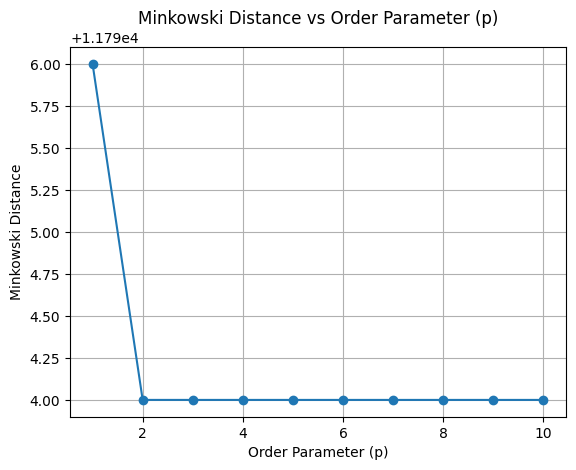

In [ ]:
# a5 AI Tool Used: ChatGPT

p_values = []
distance_values = []

for p in range(1, 11):

    distance = minkowski_distance(A, B, p)

    p_values.append(p)

    distance_values.append(distance)

plt.plot(p_values, distance_values, marker="o")

plt.title("Minkowski Distance vs Order Parameter (p)")

plt.xlabel("Order Parameter (p)")

plt.ylabel("Minkowski Distance")

plt.grid(True)

plt.show()

In [ ]:
# a6 AI Tool Used: ChatGPT

print("p\tMy Function\tPackage Function")

for p in range(1, 11):

    my_distance = minkowski_distance(A, B, p)

    package_distance = minkowski(A, B, p)

    print(p, "\t", round(my_distance, 4), "\t\t", round(package_distance, 4))

p	My Function	Package Function
1 	 11796.0 		 11796.0
2 	 11794.0001 		 11794.0001
3 	 11794.0 		 11794.0
4 	 11794.0 		 11794.0
5 	 11794.0 		 11794.0
6 	 11794.0 		 11794.0
7 	 11794.0 		 11794.0
8 	 11794.0 		 11794.0
9 	 11794.0 		 11794.0
10 	 11794.0 		 11794.0


In [ ]:
# a7 AI Tool Used: ChatGPT

def dot_product(A, B):

    return np.dot(A, B)


def euclidean_norm(A):

    return np.linalg.norm(A)


print("Dot Product")

print("My Function =", dot_product(A, B))

print("NumPy =", np.dot(A, B))

print()

print("Euclidean Norm of A")

print("My Function =", euclidean_norm(A))

print("NumPy =", np.linalg.norm(A))

print()

print("Euclidean Norm of B")

print("My Function =", euclidean_norm(B))

print("NumPy =", np.linalg.norm(B))

Dot Product
My Function = 2694347472.0
NumPy = 2694347472.0

Euclidean Norm of A
My Function = 58138.0
NumPy = 58138.0

Euclidean Norm of B
My Function = 46344.00002157777
NumPy = 46344.00002157777


In [ ]:
import numpy as np

# A8 AI Tool Used: ChatGPT

def calculate_mean(data):
    return np.mean(data)


def calculate_variance(data):
    return np.var(data)


def calculate_standard_deviation(data):
    return np.std(data)


def dataset_statistics(df):

    numerical_data = df.select_dtypes(include=np.number)

    mean_values = numerical_data.apply(calculate_mean)

    variance_values = numerical_data.apply(calculate_variance)

    standard_deviation_values = numerical_data.apply(calculate_standard_deviation)

    statistics = {
        "Mean": mean_values,
        "Variance": variance_values,
        "Standard Deviation": standard_deviation_values
    }

    return statistics


statistics = dataset_statistics(df)

print("Mean:")
print(statistics["Mean"])

print()

print("Variance:")
print(statistics["Variance"])

print()

print("Standard Deviation:")
print(statistics["Standard Deviation"])

Feature		Mean		Variance		Standard Deviation
ID 	 5592.16 	 10536109.7 	 3245.94
Year_Birth 	 1968.81 	 143.55 	 11.98
Education 	 2.39 	 1.26 	 1.12
Income 	 52247.25 	 633397830.19 	 25167.4
Kidhome 	 0.44 	 0.29 	 0.54
Teenhome 	 0.51 	 0.3 	 0.54
Recency 	 49.11 	 838.45 	 28.96
MntWines 	 303.94 	 113247.23 	 336.52
MntFruits 	 26.3 	 1581.22 	 39.76
MntMeatProducts 	 166.95 	 50924.69 	 225.66
MntFishProducts 	 37.53 	 2982.99 	 54.62
MntSweetProducts 	 27.06 	 1703.32 	 41.27
MntGoldProds 	 44.02 	 2720.23 	 52.16
NumDealsPurchases 	 2.33 	 3.73 	 1.93
NumWebPurchases 	 4.08 	 7.72 	 2.78
NumCatalogPurchases 	 2.66 	 8.54 	 2.92
NumStorePurchases 	 5.79 	 10.56 	 3.25
NumWebVisitsMonth 	 5.32 	 5.89 	 2.43
AcceptedCmp3 	 0.07 	 0.07 	 0.26
AcceptedCmp4 	 0.07 	 0.07 	 0.26
AcceptedCmp5 	 0.07 	 0.07 	 0.26
AcceptedCmp1 	 0.06 	 0.06 	 0.25
AcceptedCmp2 	 0.01 	 0.01 	 0.11
Complain 	 0.01 	 0.01 	 0.1
Z_CostContact 	 3.0 	 0.0 	 0.0
Z_Revenue 	 11.0 	 0.0 	 0.0
Response 	 0.15 	 

In [ ]:
# a9 AI Tool Used: ChatGPT

numeric_df = df.select_dtypes(include=np.number)

print("Feature\tMy Mean\tNumPy Mean\tMy Std\tNumPy Std")

for column in numeric_df.columns:

    my_mean = calculate_mean(numeric_df[column])

    numpy_mean = np.mean(numeric_df[column])

    my_std = calculate_standard_deviation(numeric_df[column])

    numpy_std = np.std(numeric_df[column])

    print(column, "\t",
          round(my_mean, 2), "\t",
          round(numpy_mean, 2), "\t",
          round(my_std, 2), "\t",
          round(numpy_std, 2))

Feature	My Mean	NumPy Mean	My Std	NumPy Std
ID 	 5592.16 	 5592.16 	 3245.94 	 3245.94
Year_Birth 	 1968.81 	 1968.81 	 11.98 	 11.98
Education 	 2.39 	 2.39 	 1.12 	 1.12
Income 	 52247.25 	 52247.25 	 25167.4 	 25167.4
Kidhome 	 0.44 	 0.44 	 0.54 	 0.54
Teenhome 	 0.51 	 0.51 	 0.54 	 0.54
Recency 	 49.11 	 49.11 	 28.96 	 28.96
MntWines 	 303.94 	 303.94 	 336.52 	 336.52
MntFruits 	 26.3 	 26.3 	 39.76 	 39.76
MntMeatProducts 	 166.95 	 166.95 	 225.66 	 225.66
MntFishProducts 	 37.53 	 37.53 	 54.62 	 54.62
MntSweetProducts 	 27.06 	 27.06 	 41.27 	 41.27
MntGoldProds 	 44.02 	 44.02 	 52.16 	 52.16
NumDealsPurchases 	 2.33 	 2.33 	 1.93 	 1.93
NumWebPurchases 	 4.08 	 4.08 	 2.78 	 2.78
NumCatalogPurchases 	 2.66 	 2.66 	 2.92 	 2.92
NumStorePurchases 	 5.79 	 5.79 	 3.25 	 3.25
NumWebVisitsMonth 	 5.32 	 5.32 	 2.43 	 2.43
AcceptedCmp3 	 0.07 	 0.07 	 0.26 	 0.26
AcceptedCmp4 	 0.07 	 0.07 	 0.26 	 0.26
AcceptedCmp5 	 0.07 	 0.07 	 0.26 	 0.26
AcceptedCmp1 	 0.06 	 0.06 	 0.25 

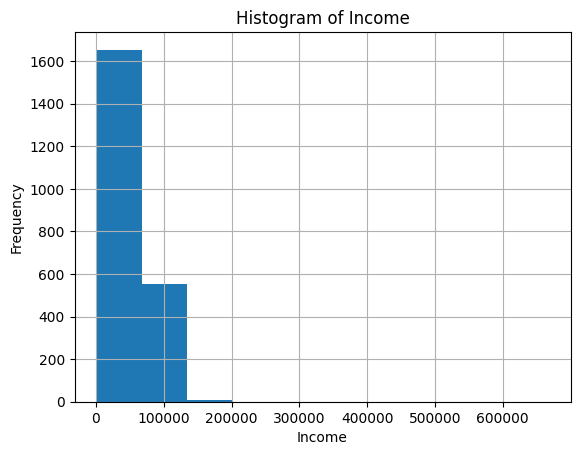

Mean = 52247.25135379061
Variance = 633397830.1872728


In [ ]:
# a10 AI Tool Used: ChatGPT

feature = df["Income"]

plt.hist(feature, bins=10)

plt.title("Histogram of Income")

plt.xlabel("Income")

plt.ylabel("Frequency")

plt.grid(True)

plt.show()

print("Mean =", np.mean(feature))

print("Variance =", np.var(feature))

In [ ]:
# A11

numeric_df = df.select_dtypes(include=np.number)
numeric_df = numeric_df.fillna(0)
kmeans = KMeans(n_clusters=3, random_state=42)
kmeans.fit(numeric_df)

print("Cluster Labels")
print(kmeans.labels_)

print()

print("Cluster Centroids")
print(kmeans.cluster_centers_)

Cluster Labels
[0 0 1 ... 0 1 0]

Cluster Centroids
[[ 5.44729941e+03  1.96586036e+03  2.53136095e+00  5.33394615e+04
   3.85798817e-01  8.08284024e-01  4.90934911e+01  3.05114793e+02
   1.99976331e+01  1.07260355e+02  2.73869822e+01  1.90804734e+01
   4.64000000e+01  3.05207101e+00  4.84023669e+00  2.37514793e+00
   6.28402367e+00  5.59408284e+00  6.50887574e-02  8.99408284e-02
   9.46745562e-03  2.13017751e-02  1.65680473e-02  7.10059172e-03
   3.00000000e+00  1.10000000e+01  1.10059172e-01  1.18343195e-03
   1.18343195e-03  1.17159763e-01  3.81065089e-01  1.95266272e-01
   2.57988166e-01  4.37869822e-02  2.36686391e-03]
 [ 5.70191720e+03  1.96773726e+03  2.47452229e+00  7.90150398e+04
   8.28025478e-02  3.24840764e-01  4.94044586e+01  6.29812102e+02
   5.90127389e+01  4.14710191e+02  8.52404459e+01  6.25557325e+01
   7.17165605e+01  1.55891720e+00  5.34872611e+00  5.60509554e+00
   8.36783439e+00  3.06847134e+00  7.16560510e-02  1.35350318e-01
   2.45222930e-01  1.95859873e-01  2.54